In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [2]:
players = pd.read_csv('basketball_data/player_stats_five_seasons.csv')
play_types = pd.read_csv('basketball_data/play_type_pct.csv')

players = players.merge(
    play_types,
    on=['PLAYER_ID', 'SEASON'],
    how='left'
)

print(f'Total player-season rows: {len(players):,}')

Total player-season rows: 2,867


In [3]:
features_all = [
    "USG_PCT", "AST_PCT",
    "SYNERGY_OFFENSIVE_CUT_PCT",
    "SYNERGY_OFFENSIVE_HANDOFF_PCT",
    "SYNERGY_OFFENSIVE_ISOLATION_PCT",
    "SYNERGY_OFFENSIVE_MISC_PCT",
    "SYNERGY_OFFENSIVE_OFFREBOUND_PCT",
    "SYNERGY_OFFENSIVE_OFFSCREEN_PCT",
    "SYNERGY_OFFENSIVE_PRBALLHANDLER_PCT",
    "SYNERGY_OFFENSIVE_PRROLLMAN_PCT",
    "SYNERGY_OFFENSIVE_POSTUP_PCT",
    "SYNERGY_OFFENSIVE_SPOTUP_PCT",
    "SYNERGY_OFFENSIVE_TRANSITION_PCT",
    "SYNERGY_DEFENSIVE_CUT_PCT",
    "SYNERGY_DEFENSIVE_HANDOFF_PCT",
    "SYNERGY_DEFENSIVE_ISOLATION_PCT",
    "SYNERGY_DEFENSIVE_MISC_PCT",
    "SYNERGY_DEFENSIVE_OFFREBOUND_PCT",
    "SYNERGY_DEFENSIVE_OFFSCREEN_PCT",
    "SYNERGY_DEFENSIVE_PRBALLHANDLER_PCT",
    "SYNERGY_DEFENSIVE_PRROLLMAN_PCT",
    "SYNERGY_DEFENSIVE_POSTUP_PCT",
    "SYNERGY_DEFENSIVE_SPOTUP_PCT",
    "SYNERGY_DEFENSIVE_TRANSITION_PCT",
]
all_features = [col for col in features_all if col in players.columns]
missing_features = [col for col in features_all if col not in players.columns]
print(f'Using {len(all_features)} available features:')
print(all_features)
if missing_features:
    print('Features not present in this dataset (omitted):', missing_features)

eligible = players[(players['POSS'] >= 10) & (players['MIN'] >= 10)].copy()
feature_data = eligible[all_features].replace([np.inf, -np.inf], np.nan)
valid_mask = feature_data.notna().all(axis=1)
eligible = eligible.loc[valid_mask].copy()
feature_data = feature_data.loc[valid_mask].copy()
print(f'Eligible player-season rows used: {len(eligible):,}')

Using 20 available features:
['USG_PCT', 'AST_PCT', 'SYNERGY_OFFENSIVE_CUT_PCT', 'SYNERGY_OFFENSIVE_HANDOFF_PCT', 'SYNERGY_OFFENSIVE_ISOLATION_PCT', 'SYNERGY_OFFENSIVE_MISC_PCT', 'SYNERGY_OFFENSIVE_OFFREBOUND_PCT', 'SYNERGY_OFFENSIVE_OFFSCREEN_PCT', 'SYNERGY_OFFENSIVE_PRBALLHANDLER_PCT', 'SYNERGY_OFFENSIVE_PRROLLMAN_PCT', 'SYNERGY_OFFENSIVE_POSTUP_PCT', 'SYNERGY_OFFENSIVE_SPOTUP_PCT', 'SYNERGY_OFFENSIVE_TRANSITION_PCT', 'SYNERGY_DEFENSIVE_HANDOFF_PCT', 'SYNERGY_DEFENSIVE_ISOLATION_PCT', 'SYNERGY_DEFENSIVE_OFFSCREEN_PCT', 'SYNERGY_DEFENSIVE_PRBALLHANDLER_PCT', 'SYNERGY_DEFENSIVE_PRROLLMAN_PCT', 'SYNERGY_DEFENSIVE_POSTUP_PCT', 'SYNERGY_DEFENSIVE_SPOTUP_PCT']
Features not present in this dataset (omitted): ['SYNERGY_DEFENSIVE_CUT_PCT', 'SYNERGY_DEFENSIVE_MISC_PCT', 'SYNERGY_DEFENSIVE_OFFREBOUND_PCT', 'SYNERGY_DEFENSIVE_TRANSITION_PCT']
Eligible player-season rows used: 2,204


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(feature_data)

kmeans = KMeans(n_clusters=6, random_state=42, n_init=20)
eligible['CLUSTER'] = kmeans.fit_predict(X_scaled)

cluster_profiles = eligible.groupby('CLUSTER')[all_features].mean()
print('Average feature values by cluster:')
display(cluster_profiles.round(3))

Average feature values by cluster:


,USG_PCT,AST_PCT,SYNERGY_OFFENSIVE_CUT_PCT,SYNERGY_OFFENSIVE_HANDOFF_PCT,SYNERGY_OFFENSIVE_ISOLATION_PCT,SYNERGY_OFFENSIVE_MISC_PCT,SYNERGY_OFFENSIVE_OFFREBOUND_PCT,SYNERGY_OFFENSIVE_OFFSCREEN_PCT,SYNERGY_OFFENSIVE_PRBALLHANDLER_PCT,SYNERGY_OFFENSIVE_PRROLLMAN_PCT,SYNERGY_OFFENSIVE_POSTUP_PCT,SYNERGY_OFFENSIVE_SPOTUP_PCT,SYNERGY_OFFENSIVE_TRANSITION_PCT,SYNERGY_DEFENSIVE_HANDOFF_PCT,SYNERGY_DEFENSIVE_ISOLATION_PCT,SYNERGY_DEFENSIVE_OFFSCREEN_PCT,SYNERGY_DEFENSIVE_PRBALLHANDLER_PCT,SYNERGY_DEFENSIVE_PRROLLMAN_PCT,SYNERGY_DEFENSIVE_POSTUP_PCT,SYNERGY_DEFENSIVE_SPOTUP_PCT
CLUSTER,,,,,,,,,,,,,,,,,,,,
0,0.171,0.102,0.187,0.003,0.014,0.088,0.165,0.004,0.005,0.222,0.091,0.132,0.089,0.016,0.204,0.016,0.037,0.133,0.135,0.451
1,0.235,0.246,0.025,0.056,0.112,0.046,0.018,0.029,0.335,0.011,0.024,0.181,0.165,0.083,0.079,0.054,0.339,0.038,0.049,0.336
2,0.164,0.117,0.198,0.002,0.017,0.090,0.161,0.005,0.006,0.199,0.064,0.116,0.097,0.005,0.080,0.008,0.576,0.082,0.036,0.198
3,0.153,0.108,0.078,0.031,0.024,0.051,0.052,0.015,0.083,0.036,0.013,0.393,0.222,0.079,0.101,0.062,0.339,0.036,0.049,0.334
4,0.151,0.123,0.022,0.018,0.006,0.008,0.011,0.008,0.135,0.019,0.002,0.545,0.166,0.015,0.036,0.001,0.340,0.002,0.008,0.544
5,0.183,0.108,0.035,0.113,0.028,0.036,0.020,0.110,0.123,0.023,0.007,0.320,0.186,0.087,0.092,0.068,0.312,0.029,0.041,0.360


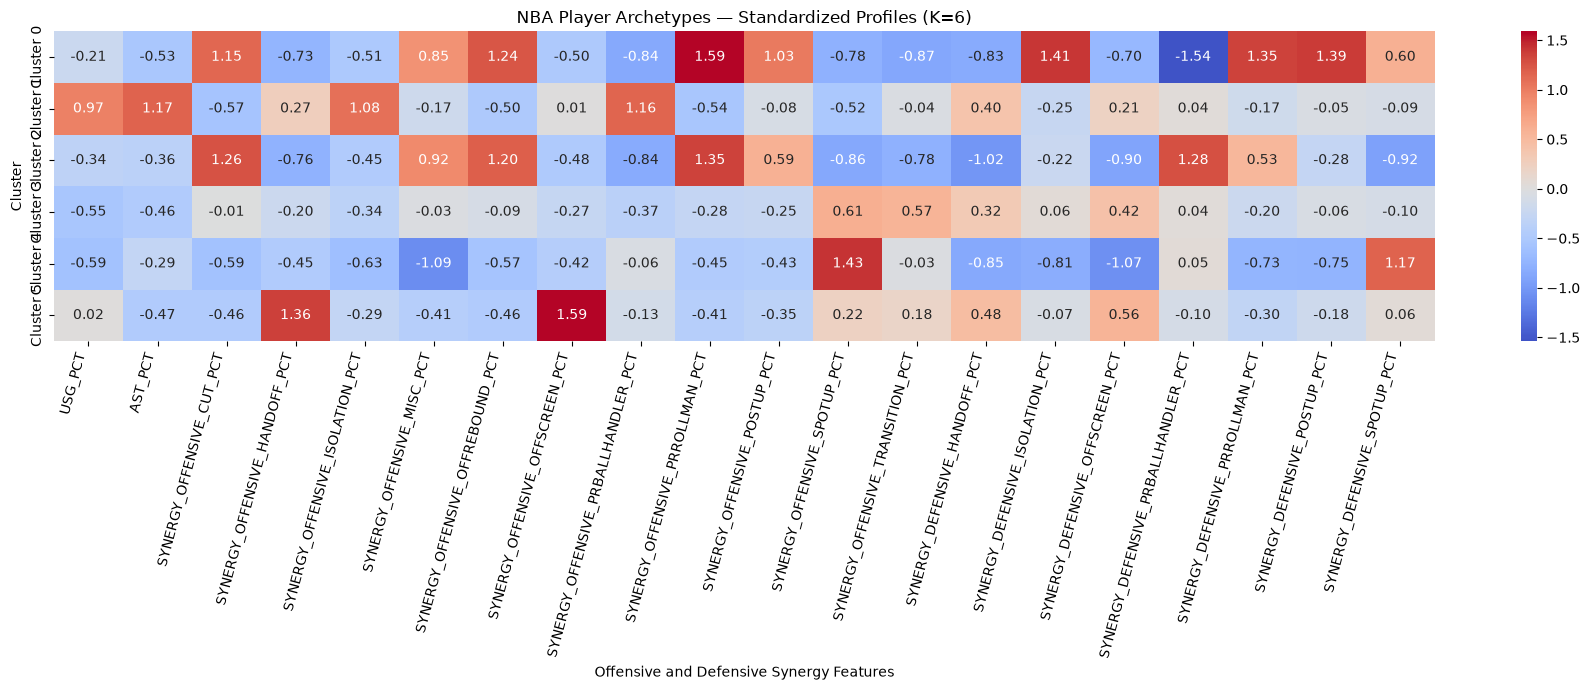

In [5]:
cluster_centers = pd.DataFrame(kmeans.cluster_centers_, columns=all_features, index=[f'Cluster {i}' for i in range(6)])

plt.figure(figsize=(18, 7))
sns.heatmap(cluster_centers, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('NBA Player Archetypes — Standardized Profiles (K=6)')
plt.xlabel('Offensive and Defensive Synergy Features')
plt.ylabel('Cluster')
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.show()

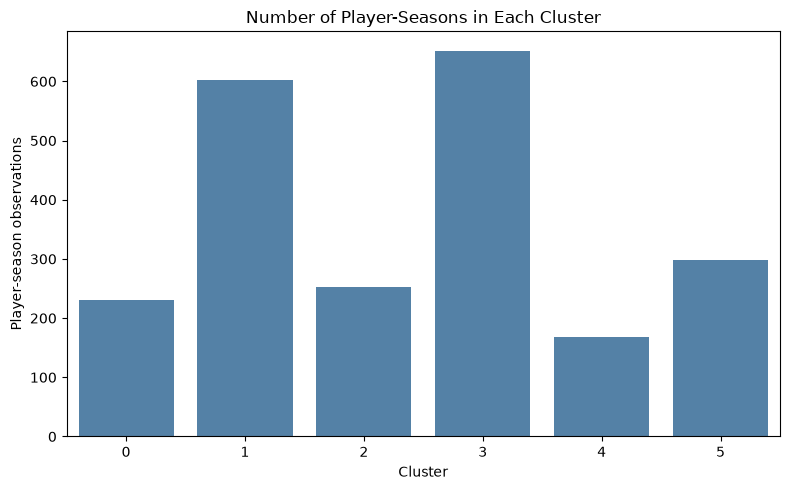

,Player-season count
CLUSTER,
0,230
1,602
2,253
3,652
4,168
5,299


In [6]:
cluster_counts = eligible['CLUSTER'].value_counts().sort_index()
plt.figure(figsize=(8, 5))
sns.barplot(x=cluster_counts.index.astype(str), y=cluster_counts.values, color='steelblue')
plt.title('Number of Player-Seasons in Each Cluster')
plt.xlabel('Cluster')
plt.ylabel('Player-season observations')
plt.tight_layout()
plt.show()
display(cluster_counts.rename('Player-season count').to_frame())

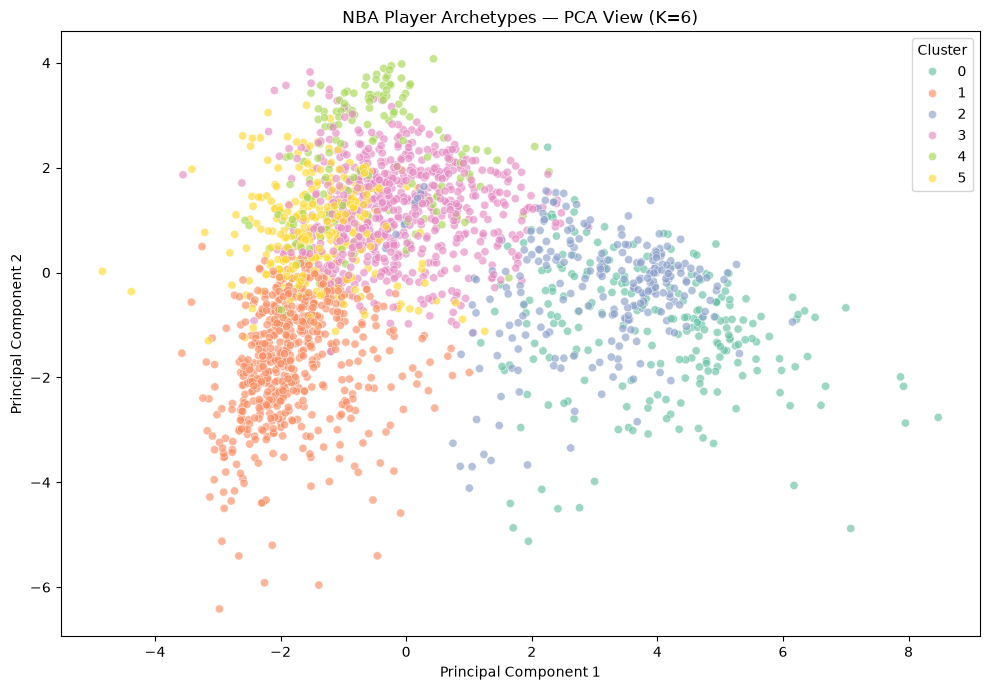

Variance explained by the first two components: 0.383


In [7]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
plot_data = eligible.copy()
plot_data['PC1'] = X_pca[:, 0]
plot_data['PC2'] = X_pca[:, 1]

plt.figure(figsize=(10, 7))
sns.scatterplot(data=plot_data, x='PC1', y='PC2', hue='CLUSTER', palette='Set2', alpha=0.65, s=35)
plt.title('NBA Player Archetypes — PCA View (K=6)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()
print('Variance explained by the first two components:', round(pca.explained_variance_ratio_.sum(), 3))

In [8]:
display_columns = [c for c in ['PLAYER_NAME', 'TEAM_ABBREVIATION', 'SEASON', 'MIN', 'PTS', 'AST', 'REB', 'CLUSTER'] if c in eligible.columns]

for cluster_id in range(6):
    print(f'\nCLUSTER {cluster_id} — 10 examples')
    examples = (eligible[eligible['CLUSTER'] == cluster_id]
                .sort_values('MIN', ascending=False)
                .head(10))
    display(examples[display_columns].reset_index(drop=True))


CLUSTER 0 — 10 examples


,PLAYER_NAME,TEAM_ABBREVIATION,SEASON,MIN,PTS,AST,REB,CLUSTER
0,Anthony Davis,LAL,2021-22,35.1,23.2,3.1,9.9,0
1,Bam Adebayo,MIA,2022-23,34.6,20.4,3.2,9.2,0
2,Domantas Sabonis,SAC,2022-23,34.6,19.1,7.3,12.3,0
3,Joel Embiid,PHI,2022-23,34.6,33.1,4.2,10.2,0
4,Evan Mobley,CLE,2022-23,34.4,16.2,2.8,9.0,0
5,Domantas Sabonis,SAC,2021-22,34.4,18.9,5.2,12.1,0
6,Nikola Vučević,CHI,2023-24,34.3,18.0,3.3,10.5,0
7,Anthony Davis,LAL,2022-23,34.0,25.9,2.6,12.5,0
8,Evan Mobley,CLE,2021-22,33.8,15.0,2.5,8.3,0
9,Joel Embiid,PHI,2021-22,33.8,30.6,4.2,11.7,0



CLUSTER 1 — 10 examples


,PLAYER_NAME,TEAM_ABBREVIATION,SEASON,MIN,PTS,AST,REB,CLUSTER
0,Zavier Simpson,OKC,2021-22,43.5,11.0,7.5,5.3,1
1,Tyrese Maxey,PHI,2025-26,38.0,28.3,6.6,4.1,1
2,Fred VanVleet,TOR,2021-22,37.9,20.3,6.7,4.4,1
3,Pascal Siakam,TOR,2021-22,37.9,22.8,5.3,8.5,1
4,DeMar DeRozan,CHI,2023-24,37.8,24.0,5.3,4.3,1
5,Tyrese Maxey,PHI,2024-25,37.7,26.3,6.1,3.3,1
6,Kyrie Irving,BKN,2021-22,37.6,27.4,5.8,4.4,1
7,Tyrese Maxey,PHI,2023-24,37.5,25.9,6.2,3.7,1
8,Luka Dončić,DAL,2023-24,37.5,33.9,9.8,9.2,1
9,Miles Bridges,CHA,2023-24,37.4,21.0,3.3,7.3,1



CLUSTER 2 — 10 examples


,PLAYER_NAME,TEAM_ABBREVIATION,SEASON,MIN,PTS,AST,REB,CLUSTER
0,Nikola Jokić,DEN,2024-25,36.7,29.6,10.2,12.8,2
1,Domantas Sabonis,SAC,2023-24,35.7,19.4,8.2,13.7,2
2,Anthony Davis,LAL,2023-24,35.5,24.7,3.5,12.6,2
3,Karl-Anthony Towns,NYK,2024-25,35.0,24.4,3.1,12.8,2
4,Nikola Jokić,DEN,2025-26,34.8,27.7,10.7,12.9,2
5,Domantas Sabonis,SAC,2024-25,34.7,19.1,6.0,13.9,2
6,Nikola Jokić,DEN,2023-24,34.6,26.4,9.0,12.4,2
7,Bam Adebayo,MIA,2024-25,34.3,18.1,4.3,9.6,2
8,Rudy Gobert,MIN,2023-24,34.1,14.0,1.3,12.9,2
9,Bam Adebayo,MIA,2023-24,34.0,19.3,3.9,10.4,2


... (2 outputs left out)


CLUSTER 4 — 10 examples


,PLAYER_NAME,TEAM_ABBREVIATION,SEASON,MIN,PTS,AST,REB,CLUSTER
0,Melvin Frazier Jr.,OKC,2021-22,39.9,10.7,0.3,4.3,4
1,Derrick Walton Jr.,DET,2021-22,36.1,6.3,7.0,3.3,4
2,Jaylen Hoard,OKC,2021-22,34.2,14.7,2.4,12.0,4
3,Devin Cannady,ORL,2021-22,28.9,10.0,2.0,1.2,4
4,Wes Iwundu,ATL,2021-22,27.4,7.3,0.0,4.3,4
5,Killian Hayes,BKN,2024-25,27.1,9.0,5.2,3.0,4
6,Javonte Green,CHI,2023-24,25.6,12.2,0.6,7.4,4
7,Tyler Burton,MEM,2025-26,25.6,10.8,1.0,4.2,4
8,Nate Williams,POR,2022-23,25.3,10.6,2.0,3.0,4
9,Timmy Allen,MEM,2023-24,25.1,2.6,1.0,3.4,4



CLUSTER 5 — 10 examples


,PLAYER_NAME,TEAM_ABBREVIATION,SEASON,MIN,PTS,AST,REB,CLUSTER
0,Mikal Bridges,BKN,2022-23,35.7,20.1,3.3,4.4,5
1,Trey Murphy III,NOP,2025-26,35.5,21.5,3.8,5.7,5
2,Gary Trent Jr.,TOR,2021-22,35.0,18.3,2.0,2.7,5
3,Trey Murphy III,NOP,2024-25,35.0,21.2,3.5,5.1,5
4,Keegan Murray,SAC,2025-26,34.5,14.0,1.7,5.7,5
5,Lauri Markkanen,UTA,2022-23,34.4,25.6,1.9,8.6,5
6,Lauri Markkanen,UTA,2025-26,34.3,26.7,2.1,6.9,5
7,Brandon Miller,CHA,2024-25,34.2,21.0,3.6,4.9,5
8,Terry Rozier,CHA,2021-22,33.7,19.3,4.5,4.3,5
9,Michael Porter Jr.,DEN,2024-25,33.7,18.2,2.1,7.0,5


In [9]:
eligible.to_csv('basketball_data/player_archetype_clusters_k6.csv', index=False)
print('Saved: basketball_data/player_archetype_clusters_k6.csv')

Saved: basketball_data/player_archetype_clusters_k6.csv
